In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline 

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5 

In [3]:
xs = np.arange(-5, 5, 0.25)
xs
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

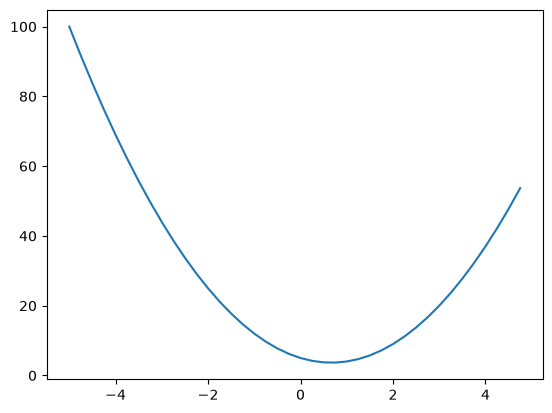

In [4]:
plt.plot(xs, ys)

In [5]:
h = 0.00000001
df = (f(xs + h) - f(xs))/h 

In [6]:
df

array([-33.99999997, -32.5000002 , -31.00000043, -29.50000066,
       -27.99999947, -26.49999971, -24.99999994, -23.50000017,
       -22.0000004 , -20.49999921, -18.99999944, -17.49999967,
       -15.9999999 , -14.50000013, -13.00000001, -11.49999989,
       -10.00000012,  -8.49999999,  -6.99999996,  -5.49999992,
        -3.99999998,  -2.49999994,  -0.99999999,   0.50000004,
         1.99999999,   3.49999993,   4.99999997,   6.5       ,
         7.99999995,   9.50000008,  10.99999984,  12.49999997,
        14.00000009,  15.49999986,  17.00000034,  18.49999904,
        20.00000023,  21.5       ,  22.99999977,  24.49999954])

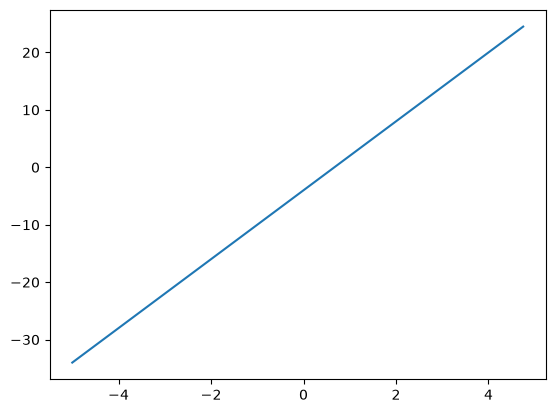

In [7]:
plt.plot(xs,df)

In [8]:
a = 2.0
b = -3.0
c = 10.0
h = 0.000001 
k = a*b + c
k1 = k
c +=h 
k2 = a*b + c

print("k1", k1)
print("k2", k2)
print("slope: ", (k2 - k1)/h)

k1 4.0
k2 4.000000999999999
slope:  0.9999999992515995


In [9]:
class Value:
    def __init__(self, data, _children =(), _op='', label =''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        self._backward = lambda:None
        
    def __repr__(self):
            return f"Value (data = {self.data})"
        
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other) 
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other) 
        out = Value(self.data * other.data, (self, other),  "*")
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
        
    def __neg__(self):
        return self * -1
        
    def __sub__(self, other):
        return self + (-other) 
        
    def __rmul__(self, other):
        return self * other
        
    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other) 
        out = Value(self.data / other.data, (self,other), '/')
        def _backward():
            self.grad += (1/other.data) * out.grad
            other.grad += ((-self.data)/(other.data**2)) * out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other
    
    def __rsub__(self, other):
        return other + (-self)
    
    def __rtruediv__(self, other):
        return other * self ** -1

    def __pow__(self, other):
        other = other if isinstance(other, Value) else Value(other) 
        out = Value(self.data ** other.data, (self, other), '**')
        def _backward():
            self.grad += other.data * (self.data ** (other.data - 1) ) * out.grad
            other.grad += out.data *  np.log(self.data) * out.grad
        out._backward = _backward
        return out
        
    def tanh(self):
        out = Value((np.e ** (2 * self.data) - 1) / (np.e ** (2*self.data) + 1),  (self, )  ,"tanh")
        def _backward():
            self.grad += (1 - out.data ** 2) * out.grad
        out._backward = _backward
        return out
    
    def exp(self):
        out = Value(np.e ** self.data, (self, ), "exp")
        def _backward():
            self.grad += out.data * out.grad 
        out._backward = _backward
        return out
    def __hash__(self):
        return id(self)
    def backward(self):
        topo = [] 
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1
        for node in reversed(topo):
            node._backward()
    
        

In [10]:
a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10, label = 'c')
e = a*b; e.label = 'e'
f = Value(-2.0, label ='f')
d = e + c; d.label = 'd'
L = d * f; L.label = 'L'
y = L.tanh(); y.label ='y'

In [11]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges
def draw_dot(root):
    dot = Digraph(format ="svg", graph_attr={'rankdir': 'LR'}) #LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad) , shape="record")
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid+n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

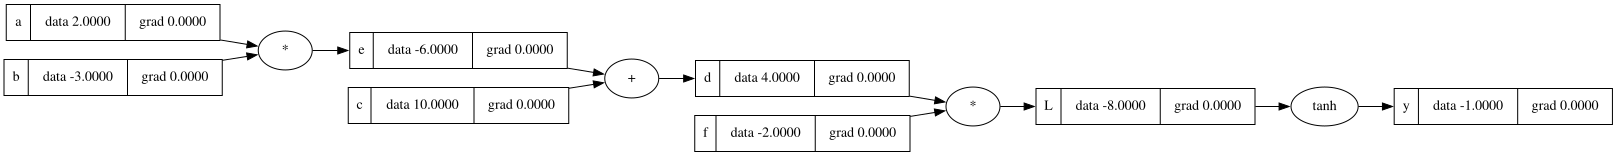

In [12]:
draw_dot(y)

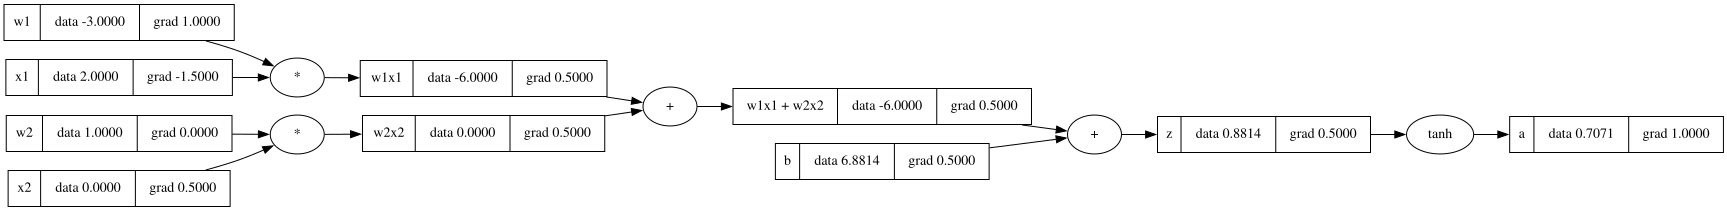

In [13]:

x1 = Value(2.0, label = 'x1')
x2 = Value(0, label = 'x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label ='w2')

b = Value(6.8813735, label ='b')

w1x1 = w1 * x1;  w1x1.label ='w1x1'
w2x2 = w2 * x2; w2x2.label ='w2x2'

ws = w1x1 + w2x2; ws.label = 'w1x1 + w2x2'
z = ws + b; z.label = 'z'

a = z.tanh(); a.label='a'

a.backward()


draw_dot(a)

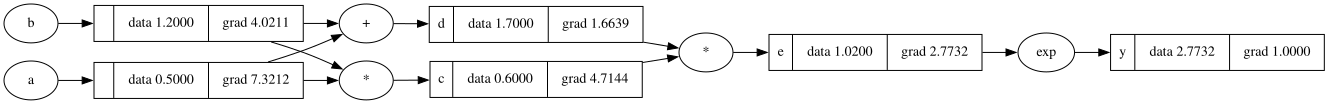

In [14]:
a = Value(0.5,(), 'a')
b = Value (1.2, (),'b')
c = a * b; 
c.label = 'c'
d = a + b;
d.label = 'd'
e = c * d; e.label = 'e'
y =  e.exp()
y.label = 'y'

y.backward()

draw_dot(y)

In [15]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))
    def __call__(self, x):
            out = sum((wi * xi for wi, xi in zip(self.w,x)), self.b)
            return out.tanh()
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    def parameters(self):
       return [p for neuron in self.neurons for p in neuron.parameters()]
        
class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [(Layer(sz[i], sz[i+1])) for i in range(len(nouts))]
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [16]:
x = [-1, 2, 3]
n = MLP(3, [4,4,1])

In [17]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0,  -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0]

ypred = [n(x) for x in xs]
ypred

[Value (data = 0.5672396527066351),
 Value (data = 0.6485218527955157),
 Value (data = 0.32349950524821025),
 Value (data = 0.6015793773184998)]

In [18]:
n.parameters()

[Value (data = -0.10187130460346228),
 Value (data = 0.03682135533747988),
 Value (data = 0.23555620675236044),
 Value (data = 0.5368526989048596),
 Value (data = -0.25631114765895946),
 Value (data = -0.3922806691171905),
 Value (data = 0.024775433007677483),
 Value (data = -0.9378144991375299),
 Value (data = 0.17647390155723164),
 Value (data = -0.40865086617801016),
 Value (data = -0.4599473365639488),
 Value (data = -0.21916232756097487),
 Value (data = -0.7628685534901183),
 Value (data = -0.08500886417206521),
 Value (data = 0.9103846909460684),
 Value (data = 0.11816068240809119),
 Value (data = -0.44005597020314524),
 Value (data = 0.8094487770097467),
 Value (data = -0.7176745452386661),
 Value (data = -0.20804157545502422),
 Value (data = -0.20563547012324968),
 Value (data = 0.22026812098073778),
 Value (data = 0.5176441240895824),
 Value (data = 0.6266399048075058),
 Value (data = 0.41319857747693867),
 Value (data = 0.793385242130312),
 Value (data = -0.23127792230392918)

In [19]:
loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))
loss

Value (data = 4.8152957503040055)

In [20]:
loss.backward()

/tmp/ipykernel_951927/3196254582.py:63: RuntimeWarning: invalid value encountered in log
  other.grad += out.data *  np.log(self.data) * out.grad


In [21]:
for k in range(50):
    #forward
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))
    #zero grads
    for p in n.parameters():
        p.grad = 0.0
    #backward
    loss.backward()
    for p in n.parameters():
        p.data += -0.01 * p.grad

/tmp/ipykernel_951927/3196254582.py:63: RuntimeWarning: invalid value encountered in log
  other.grad += out.data *  np.log(self.data) * out.grad


In [22]:
loss

Value (data = 0.16283985811791085)